# Dataset "Two Moons" con Niveles Variables de Ruido

## 1. Generación del dataset

`sklearn.datasets.make_moons(n_samples, noise, ...)` genera dos semicírculos
entrelazados en $\mathbb{R}^2$. El parámetro `noise` añade ruido gaussiano
isotrópico a las coordenadas:

$$
(x_i, y_i) = (x_i^{\text{limpio}}, y_i^{\text{limpio}}) + \varepsilon_i,
\qquad \varepsilon_i \sim \mathcal{N}\!\left(\mathbf{0},\, \sigma^2 I_2\right),
$$

con $\sigma = $ `noise`. Un valor de `noise = 0` produce dos lunas perfectas;
a medida que `noise` crece, las lunas se **solapan** y el problema se vuelve
progresivamente más difícil.

## 2. ¿Por qué "two moons"?

Cada clase ocupa un semicírculo:

$$
\text{Clase } 0: \quad (x,y) = (r\cos\theta,\; r\sin\theta), \quad \theta \in [0,\pi],
$$

$$
\text{Clase } 1: \quad (x,y) = (1 - r\cos\theta,\;\, r\sin\theta - \tfrac{1}{2}),
\quad \theta \in [0,\pi],
$$

con $r = 1$ (radio). El resultado son dos medias lunas entrelazadas que
**ningún clasificador lineal** puede separar bien — por eso son un test
canónico para modelos no lineales como k-NN, SVM con kernel RBF, o árboles.

## 3. Efecto del ruido

| `noise` | Descripción              | Dificultad              |
|---------|--------------------------|-------------------------|
| 0.00    | Lunas perfectas          | Trivial (accuracy ~1.0) |
| 0.05    | Ruido mínimo             | Muy fácil               |
| 0.10    | Ruido bajo               | Fácil                   |
| 0.20    | Ruido moderado           | Media                   |
| 0.30    | Ruido alto               | Difícil                 |
| 0.50    | Solapamiento severo      | Muy difícil (cerca del azar) |

El **accuracy de test** de cualquier clasificador cae monótonamente con `noise`.
Además, el **óptimo de complejidad** del modelo (por ejemplo, el mejor $k$ de
k-NN) **aumenta** con el ruido: con más ruido conviene suavizar más.

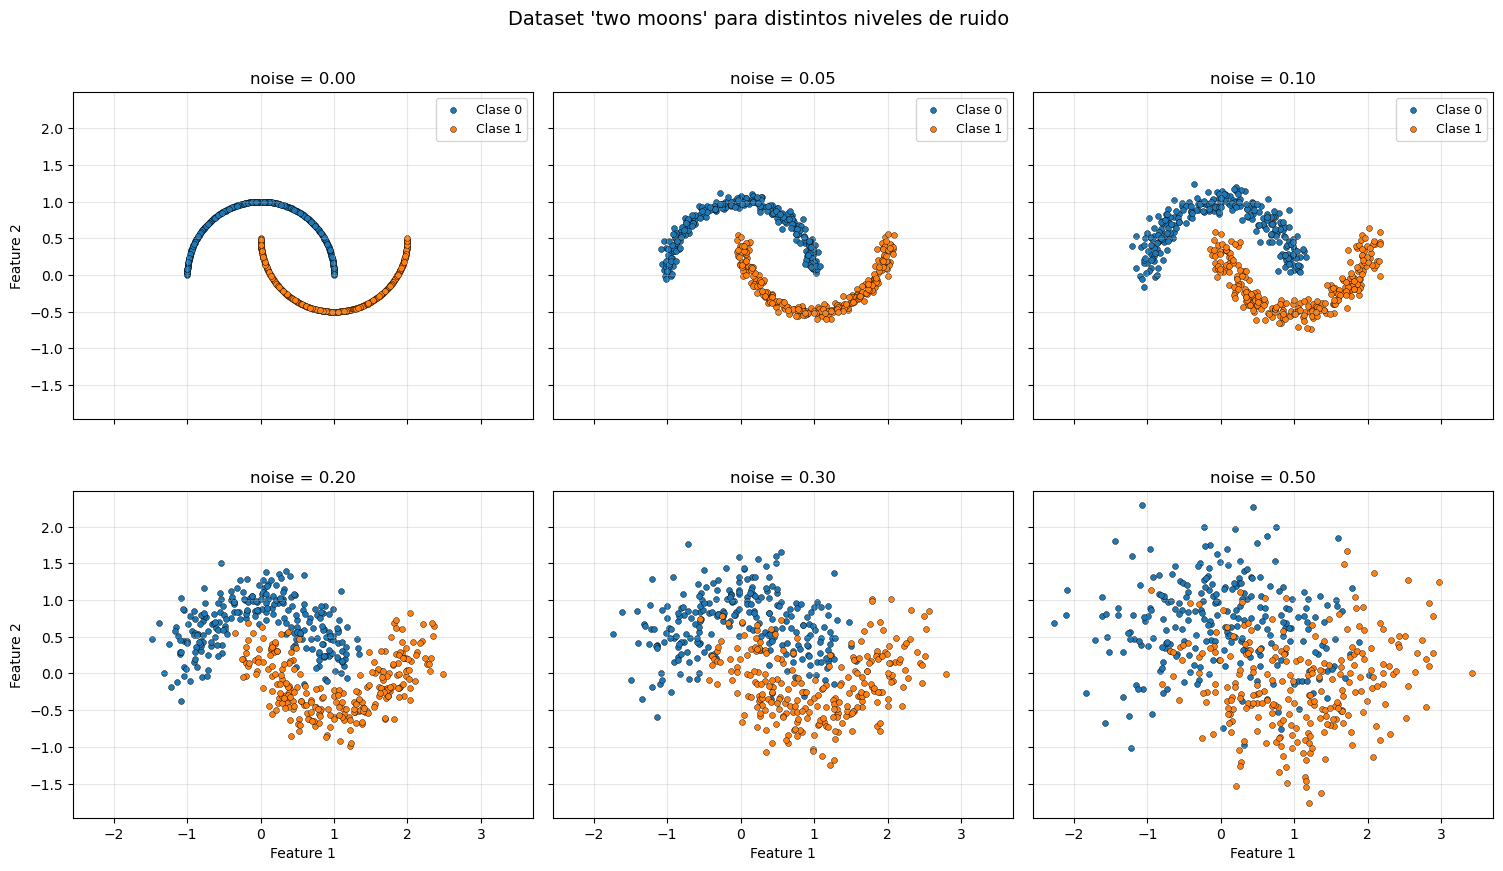

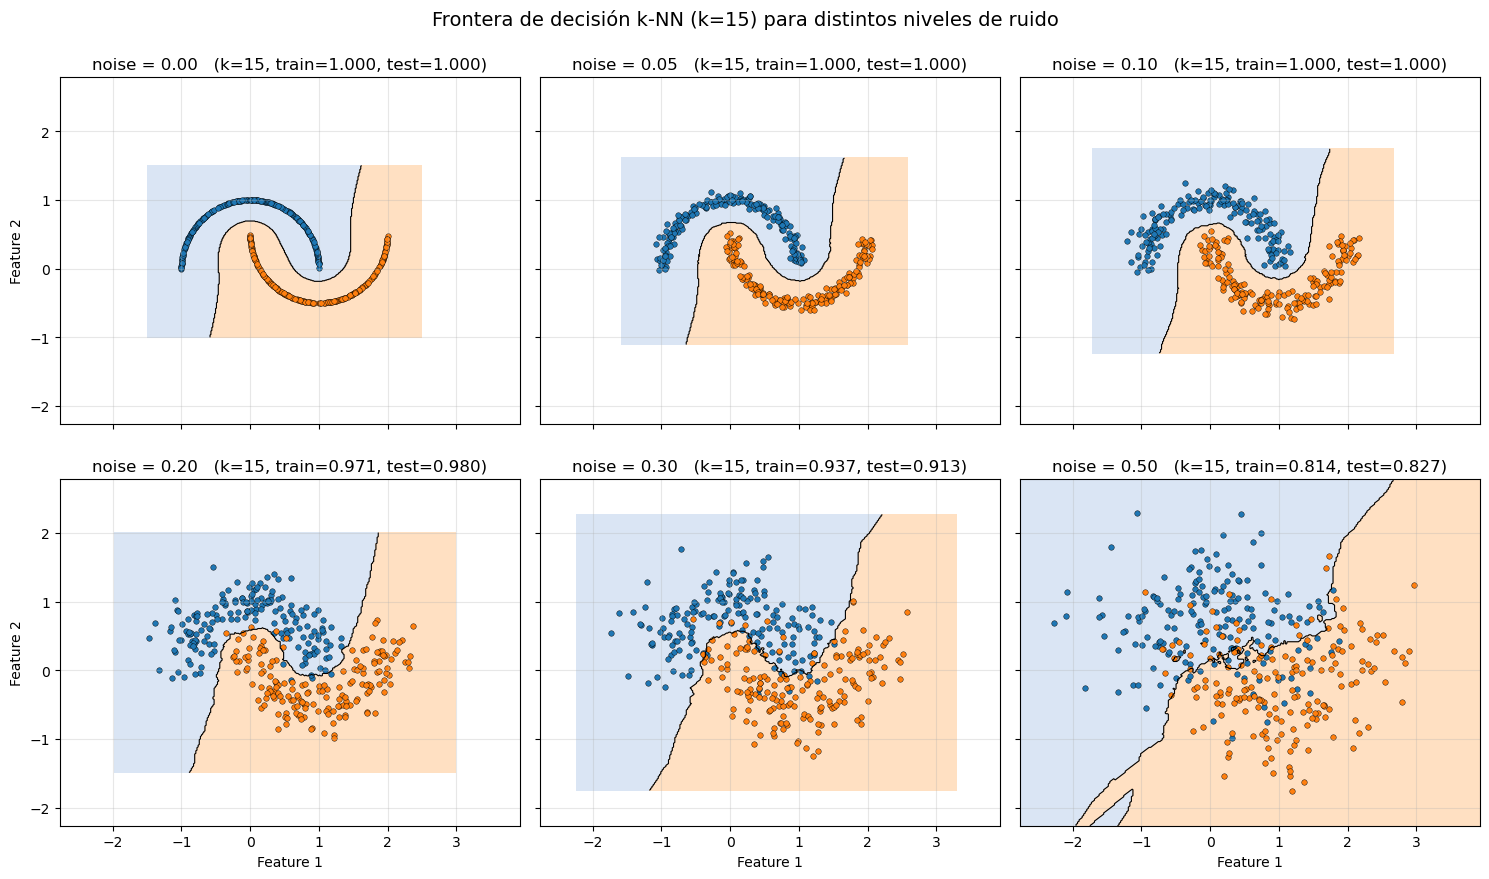

In [1]:
# =============================================================================
# DATASET "TWO MOONS" CON DIFERENTES NIVELES DE RUIDO
# =============================================================================
# Ilustra cómo el parámetro `noise` de make_moons afecta:
#   * la geometría del dataset,
#   * la frontera de decisión de un clasificador k-NN,
#   * el accuracy de train/test.
#
# Requiere: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# ---------------------------------------------------------------------------
# 1. Parámetros
# ---------------------------------------------------------------------------
RANDOM_SEED = 42
N_SAMPLES   = 500
NOISE_LEVELS = [0.00, 0.05, 0.10, 0.20, 0.30, 0.50]

cmap_pts = ListedColormap(["#1f77b4", "#ff7f0e"])
cmap_bg  = ListedColormap(["#aec7e8", "#ffbb78"])


# ---------------------------------------------------------------------------
# 2. Figura 1: dataset para cada nivel de ruido
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, noise in zip(axes.ravel(), NOISE_LEVELS):
    X, y = make_moons(n_samples=N_SAMPLES, noise=noise,
                      random_state=RANDOM_SEED)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=18, c="#1f77b4",
               edgecolor="k", linewidth=0.3, label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=18, c="#ff7f0e",
               edgecolor="k", linewidth=0.3, label="Clase 1")
    ax.set_title(f"noise = {noise:.2f}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

for ax in axes[0]:
    ax.legend(loc="upper right", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Feature 1")
for ax in axes[:, 0]:
    ax.set_ylabel("Feature 2")

fig.suptitle("Dataset 'two moons' para distintos niveles de ruido",
             fontsize=14)
plt.tight_layout()
plt.savefig("two_moons_noise_levels.png", dpi=120)
plt.show()


# ---------------------------------------------------------------------------
# 3. Figura 2: frontera de decisión k-NN sobre cada nivel de ruido
# ---------------------------------------------------------------------------
K_NEIGHBORS = 15

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, noise in zip(axes.ravel(), NOISE_LEVELS):
    X, y = make_moons(n_samples=N_SAMPLES, noise=noise,
                      random_state=RANDOM_SEED)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y)

    model = KNeighborsClassifier(n_neighbors=K_NEIGHBORS).fit(X_tr, y_tr)
    acc_tr = accuracy_score(y_tr, model.predict(X_tr))
    acc_te = accuracy_score(y_te, model.predict(X_te))

    # Rejilla para la frontera
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg,
                levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5])
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], s=16,
               c="#1f77b4", edgecolor="k", linewidth=0.3)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], s=16,
               c="#ff7f0e", edgecolor="k", linewidth=0.3)

    ax.set_title(f"noise = {noise:.2f}   "
                 f"(k={K_NEIGHBORS}, train={acc_tr:.3f}, "
                 f"test={acc_te:.3f})")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

for ax in axes[-1]:
    ax.set_xlabel("Feature 1")
for ax in axes[:, 0]:
    ax.set_ylabel("Feature 2")

fig.suptitle(f"Frontera de decisión k-NN (k={K_NEIGHBORS}) "
             f"para distintos niveles de ruido", fontsize=14)
plt.tight_layout()
plt.savefig("two_moons_knn_boundaries.png", dpi=120)
plt.show()